## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Zoe Edelblum

**Date:** 10/21

In [4]:
# Your Phase 1 solution to the problem goes here.
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

## Q1: Token frequencies

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598)]


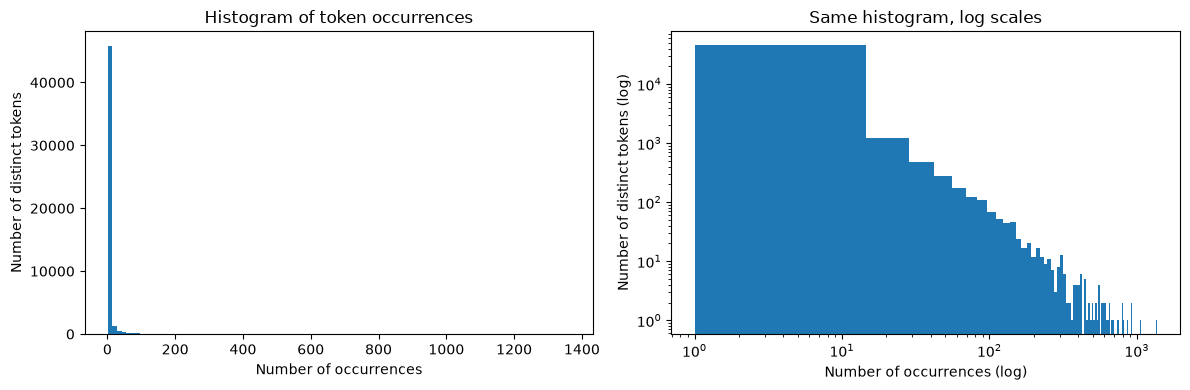

In [ ]:
with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
print(token_freq[:20])

counts = [c for _, c in token_freq]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(counts, bins=100)
ax[0].set_title('Histogram of token occurrences')
ax[0].set_xlabel('Number of occurrences')
ax[0].set_ylabel('Number of distinct tokens')

ax[1].hist(counts, bins=100, log=True)
ax[1].set_xscale('log')
ax[1].set_title('Same histogram, log scales')
ax[1].set_xlabel('Number of occurrences (log)')
ax[1].set_ylabel('Number of distinct tokens (log)')
plt.tight_layout()
plt.show()

The distribution of token frequencies is extremely right-skewed and heavy-tailed. Almost all distinct tokens (on the order of 45,000, the entire leftmost bin) appear only a handful of times, while a very small number of tokens appear hundreds or even over a thousand times (the most common, "new", appears about 1,365 times). On the log-log plot the counts fall off roughly along a straight line, which is the signature of a power-law (Zipf-like) distribution. A few words dominate and there is a very long tail of rare words. This is why the feature matrix in Q2 keeps only tokens that appear in at least 15 e-mails. The rare tokens carry little usable signal.

## Q2: Linear regression on one-hot-encoded tokens

In [6]:
df = pd.read_parquet('data/Phishing_clean.parquet', engine='fastparquet')
y = df['Email Type']
X = df.drop(columns=['Email Type'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lm = LinearRegression()
lm.fit(X_train, y_train)
print('Train R^2:', lm.score(X_train, y_train))
print('Test  R^2:', lm.score(X_test, y_test))

coefs = pd.Series(lm.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
print(top.head(20))

Train R^2: 0.7670143724934355
Test  R^2: 0.6658718438847919
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
shopper             -0.486678
april's             -0.486483
arial,              -0.482141
laser                0.473607
issue:              -0.465547
dtype: float64


**Train R²:** 0.767

**Test R²:** 0.666

**Comparison:** The model explains about 77% of the variance in the training set but only about 67% on held-out emails. The gap of roughly 10 percentage points suggests some overfitting, which is expected when a regression has about 2,700 features and relatively few emails. It still generalizes reasonably well, since the test R² is high.

**Words with the largest absolute coefficients:** "intervention" (-1.26), "localized" (0.82), "thermal" (0.75), "crawler" (0.70), "background-image:" (-0.62), "helvetica," (0.60), "aging" (0.59), "form." (0.58), "gray;" (-0.57), and "a:active" (0.57). Positive coefficients push the prediction toward phishing (1) and negative ones toward non-phishing (0).

**Interpretation:** These top words are not an obviously intuitive list of "scam words." Several are HTML or CSS fragments ("background-image:", "helvetica,", "gray;", "a:active", "{text-decoration:", "arial,"), which reflect how an email was formatted rather than what it says. Others ("intervention", "localized", "thermal", "crawler", "aging") look like topic words from particular email sources. Because the tokens are rare and correlated, individual coefficients in an unregularized regression with this many features are unstable, so a large coefficient does not necessarily mean a word is truly the most important signal. This is also a good motivation for the PCA approach in Q4.

## Q3: PCA with two components

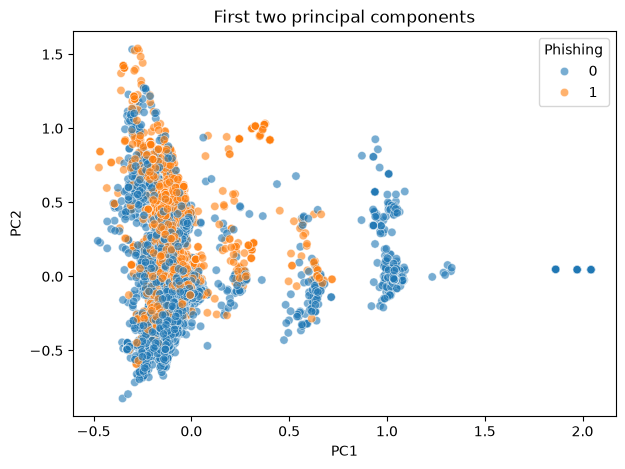

Explained variance ratio: [0.0111309  0.00861214]


In [7]:
pca2 = PCA(n_components=2)
Z = pca2.fit_transform(X)

plot_df = pd.DataFrame({'PC1': Z[:, 0], 'PC2': Z[:, 1], 'Phishing': y.values})

plt.figure(figsize=(7, 5))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='Phishing', alpha=0.6)
plt.title('First two principal components')
plt.show()

print('Explained variance ratio:', pca2.explained_variance_ratio_)

The first two principal components explain very little of the variance: about 1.1% (PC1) and 0.9% (PC2), or roughly 2% combined. That is expected for sparse one-hot text data with thousands of features, since the variation is spread across many dimensions and two components cannot capture most of it.

Patterns in the plot:
- **Partial separation, with heavy overlap.** Most emails sit in a dense cluster at the left (PC1 between about -0.5 and 0). Phishing emails (orange) are concentrated toward the upper part of that cluster (higher PC2), while non-phishing emails (blue) are more common toward the bottom, but the two classes overlap substantially there. Two components alone cannot cleanly separate them.

- **Distinct side clusters.** Several small groups extend to the right along PC1 (around 0.6, 1.0, and 1.3 to 2.0). The groups near PC1 of 0.5 to 1.0 and the far-right points are mostly non-phishing, while some of the small groups around PC1 of 0.2 to 0.6 are mostly phishing. These look like groups of near-duplicate or templated emails that share many of the same tokens.

- **Takeaway.** There is some class structure in the leading components, but the signal is spread across many dimensions, which is why the later components are needed for prediction in Q4.

## Q4: Regression on the first 2,610 principal components

In [ ]:
n_comp = 2610

pca = PCA(n_components=n_comp)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

lm_pca = LinearRegression()
lm_pca.fit(Z_train, y_train)
print('Train R^2 (PCA regression):', lm_pca.score(Z_train, y_train))
print('Test  R^2 (PCA regression):', lm_pca.score(Z_test, y_test))

Train R^2 (PCA regression): 0.7662326827745849
Test  R^2 (PCA regression): 0.6683390643101164


**Train R² (PCA regression):** 0.766

**Test R² (PCA regression):** 0.668

**Comparison to the original regression (Q2):** The performance is essentially identical. Train R² is 0.766 vs. 0.767 and test R² is 0.668 vs. 0.666. The test R² is marginally higher with PCA, but a difference of about 0.002 is too small to call a real improvement. The train/test gap (about 10 percentage points) is also the same, so using 2,610 components did not reduce overfitting here. This makes sense because 2,610 components is nearly all of the original 2,711 dimensions. PCA is only a rotation of the data, so keeping almost every component retains almost all of the information, and a linear regression on them is nearly the same model as the original. The small differences come from the roughly 100 dropped low-variance components.

## Q5: Why use principal components for high-dimensional regression?

The original one-hot token matrix has a very large number of columns (2,711), many of them rare, highly correlated, and mostly zeros. An ordinary regression on this data has a very large number of parameters, so it can fit noise in the training data (overfit), and its coefficients become unstable and hard to interpret. Principal components re-express the data as a set of uncorrelated directions ordered by how much variation they capture. Regressing on the top components keeps most of the useful signal, removes the multicollinearity, and drops the low-variance directions that mostly carry noise. This reduces the number of parameters, which can improve out-of-sample performance and makes the model cheaper to fit. The trade-off is that each component is a combination of many words, so individual coefficients are less directly interpretable. In this assignment, keeping 2,610 of 2,711 components gave nearly the same R² as the original regression (test R² of 0.668 vs. 0.666). This shows that most of PCA's advantage comes from keeping substantially fewer components, not from the rotation itself.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]